# Compare observation units and modalities

Recompute one case, then inspect all precomputed experimental rows. Counts of variants are not participant sample sizes.

In [1]:
from pathlib import Path
import json, sys
import pandas as pd
ROOT = Path.cwd()
if not (ROOT / 'data').exists(): ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.metrics import *


In [2]:
from scripts.run_experiments import mutate, assets
c = json.loads((ROOT/'data/processed/the_intercept.contexts.json').read_text())[0]
v, _ = mutate(c, 'collapse', 1.0, 0)
pd.Series(profile(c,v,assets(c),assets(c),{}))

asset_word             0.000000
asset_char             0.000000
asset_tfidf            0.000000
paired_word            0.466102
paired_char            0.447987
transition             0.666667
retention              0.500000
outcome_loss           0.500000
option_count_change    0.000000
dtype: float64

In [3]:
rows=pd.read_csv(ROOT/'results/metric_rows.csv.gz')
facts=json.loads((ROOT/'results/facts.json').read_text())
assert len(rows)==facts['attempted_rows']
pd.Series(facts)

contexts                      234
edges                         679
attempted_rows              11466
eligible_rows               10277
excluded_noop_rows           1189
eligible_structural_rows     9341
negative_control_rows         936
dtype: int64

In [4]:
d=pd.read_csv(ROOT/'results/detection_summary.csv')
d.pivot_table(index=['game','operation'],columns='metric',values='nonzero_rate').round(4)

metric                    asset_char  asset_tfidf  ...  paired_word  transition
game          operation                            ...                         
emoji         collapse           0.0          0.0  ...          0.0         1.0
              drop               0.0          0.0  ...          1.0         1.0
              duplicate          0.0          0.0  ...          0.0         0.0
              identity           0.0          0.0  ...          0.0         0.0
              permute            0.0          0.0  ...          0.0         1.0
              reorder            0.0          0.0  ...          0.0         0.0
              typography         1.0          0.0  ...          0.0         0.0
the_intercept collapse           0.0          0.0  ...          1.0         1.0
              drop               0.0          0.0  ...          1.0         1.0
              duplicate          0.0          0.0  ...          0.0         0.0
              identity           0.0          0.0  ...          0.0         0.0
              permute            0.0          0.0  ...          1.0         1.0
              reorder            0.0          0.0  ...          0.0         0.0
              typography         1.0          0.0  ...          0.0         0.0

[14 rows x 6 columns]

### Challenge the claim
The paired word baseline detects the tested prose edits. The inventory baseline is blind by design. Perfect aligned-pair sensitivity follows mathematically from the eligibility definition. None is an originality classification accuracy.

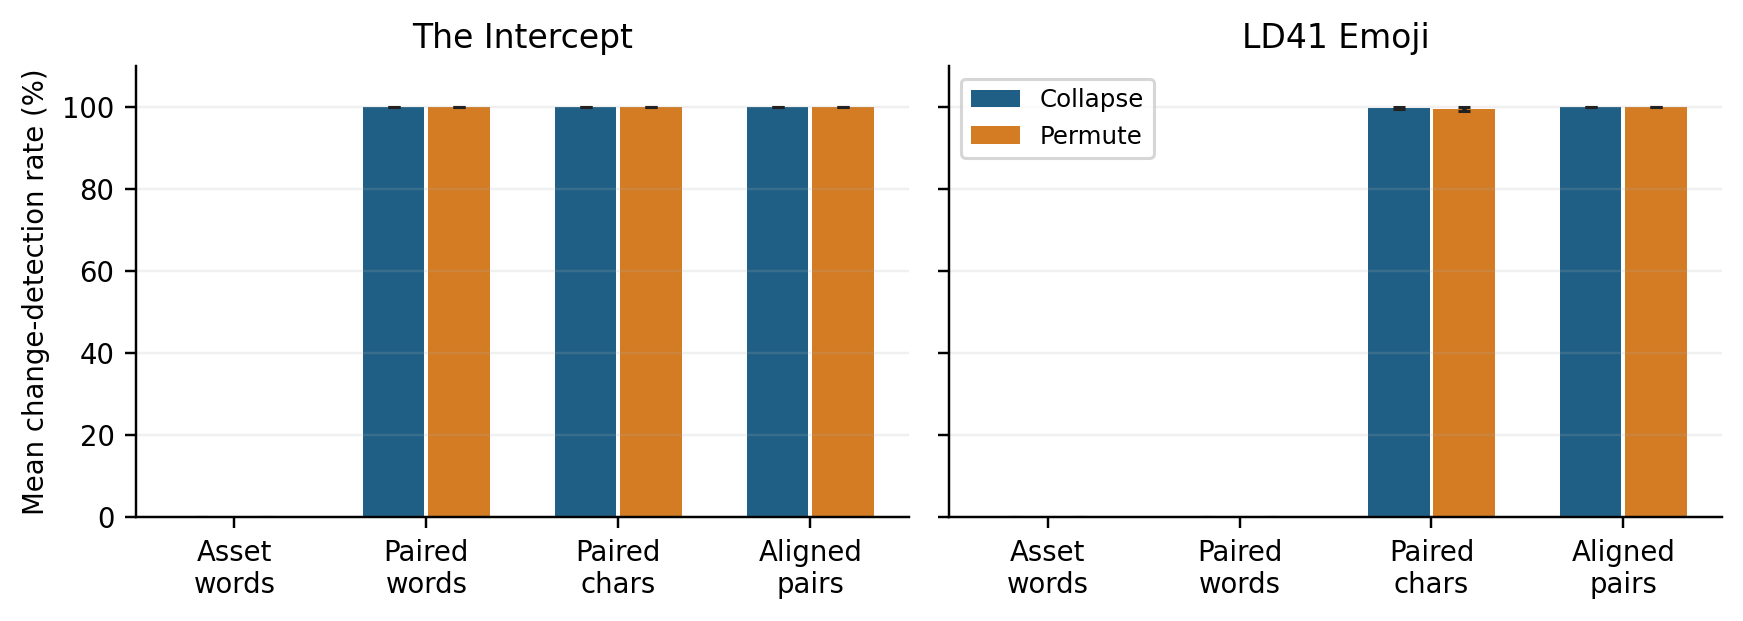

In [5]:
from IPython.display import Image, display
display(Image(filename=str(ROOT/'figures/detection.png')))

In [6]:
perm=rows[(rows.operation=='permute') & rows.eligible]
assert perm.outcome_loss.abs().max()<1e-12
perm.groupby('game')[['transition','outcome_loss']].mean()

,transition,outcome_loss
game,,
emoji,0.903598,0.0
the_intercept,0.862328,0.0
